# Proyek Klasifikasi Gambar: Animals-10
- **Nama:** Fadli Fais Fajarudin
- **Email:** novaatalagrab@gmail.com
- **ID Dicoding:** [fadly_fais](https://www.dicoding.com/users/fadly_fais)

## Import Semua Packages/Library yang Digunakan

In [ ]:
!pip install -q kagglehub tensorflowjs

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.2/15.2 MB 55.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.8/108.8 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
xarray 2025.12.0 requires packaging>=24.1, but you have packaging 20.9 which is incompatible.
langchain-core 1.6.12 requires packaging>=23.2.0, but you have packaging 20.9 which is incompatible.
astropy 7.2.3 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
pandas-gbq 0.30.0 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
db-d

In [ ]:
import os
import shutil
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, BatchNormalization,
                                     GlobalAveragePooling2D, Dense, Dropout, Rescaling)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Data Preparation

### Data Loading

Dataset yang digunakan adalah **Animals-10** (10 kelas hewan, sekitar 26.000 gambar) dari Kaggle. Gambar berasal dari web sehingga resolusinya tidak seragam. Dataset asli **tidak diubah**, dan semua perubahan ukuran hanya dilakukan saat gambar dimuat ke model.

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download("viratkothari/animal10")
print("Dataset diunduh ke:", dataset_path)

100%|██████████| 585M/585M [00:09<00:00, 64.2MB/s]

Extracting files...


Dataset diunduh ke: /root/.cache/kagglehub/datasets/viratkothari/animal10/versions/1


In [ ]:
IMG_EXT = ('.jpg', '.jpeg', '.png')

def find_class_root(base):
    """Cari folder yang berisi subfolder per kelas (masing-masing berisi gambar)."""
    for root, dirs, _ in os.walk(base):
        if len(dirs) >= 3 and all(
            any(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(root, d)))
            for d in dirs
        ):
            return root
    raise FileNotFoundError("Folder kelas tidak ditemukan, cek struktur dataset.")

DATA_DIR = find_class_root(dataset_path)
print("Folder dataset:", DATA_DIR)
print("Kelas (nama asli):", sorted(os.listdir(DATA_DIR)))

Folder dataset: /root/.cache/kagglehub/datasets/viratkothari/animal10/versions/1/Animals-10
Kelas (nama asli): ['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']


In [ ]:
def print_images_resolution(directory):
    unique_sizes = Counter()
    total_images = 0

    for subdir in sorted(os.listdir(directory)):
        subdir_path = os.path.join(directory, subdir)
        if not os.path.isdir(subdir_path):
            continue
        image_files = os.listdir(subdir_path)
        print(f"{subdir}: {len(image_files)}")
        total_images += len(image_files)

        for img_file in image_files:
            with Image.open(os.path.join(subdir_path, img_file)) as img:
                unique_sizes[img.size] += 1

    print(f"\nTotal gambar: {total_images}")
    print(f"Jumlah ukuran resolusi unik: {len(unique_sizes)}")
    print("5 ukuran paling sering:", unique_sizes.most_common(5))
    widths = [s[0] for s in unique_sizes.elements()]
    heights = [s[1] for s in unique_sizes.elements()]
    print(f"Lebar  min/max: {min(widths)} / {max(widths)}")
    print(f"Tinggi min/max: {min(heights)} / {max(heights)}")

print_images_resolution(DATA_DIR)

butterfly: 2112
cat: 1668
chicken: 3098
cow: 1866
dog: 4863
elephant: 1446
horse: 2623
sheep: 1820
spider: 4821
squirrel: 1862

Total gambar: 26179
Jumlah ukuran resolusi unik: 1002
5 ukuran paling sering: [((300, 225), 4397), ((300, 200), 3281), ((300, 300), 1192), ((300, 169), 1048), ((640, 426), 694)]
Lebar  min/max: 60 / 6720
Tinggi min/max: 57 / 6000


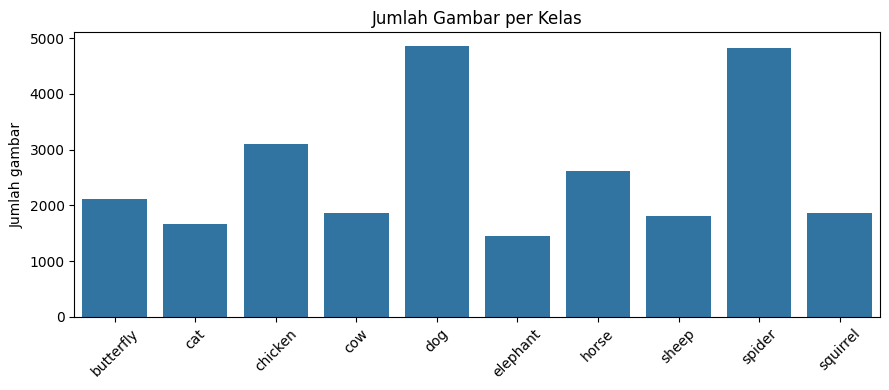

In [ ]:
# Distribusi jumlah gambar per kelas
counts = {d: len(os.listdir(os.path.join(DATA_DIR, d)))
          for d in sorted(os.listdir(DATA_DIR)) if os.path.isdir(os.path.join(DATA_DIR, d))}

plt.figure(figsize=(9, 4))
sns.barplot(x=list(counts.keys()), y=list(counts.values()))
plt.title("Jumlah Gambar per Kelas")
plt.xticks(rotation=45)
plt.ylabel("Jumlah gambar")
plt.tight_layout()
plt.show()

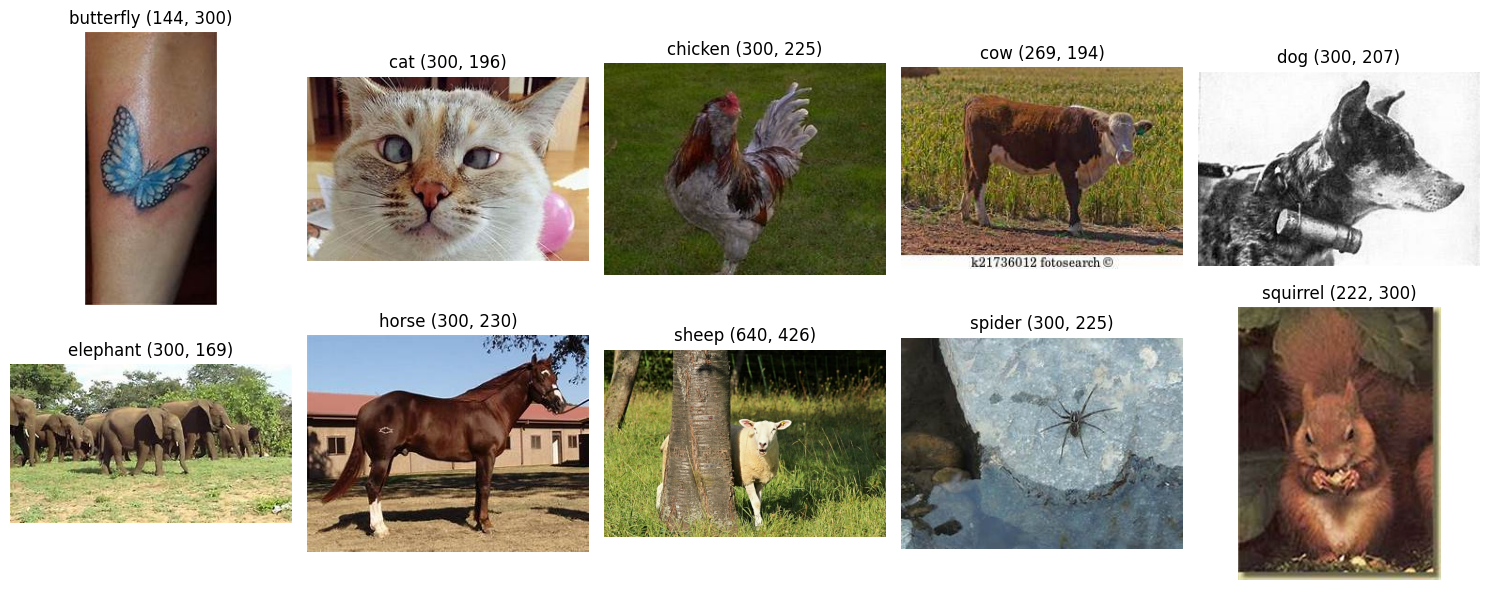

In [ ]:
# Contoh gambar dari tiap kelas
classes_raw = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, c in zip(axes.ravel(), classes_raw):
    f = random.choice(os.listdir(os.path.join(DATA_DIR, c)))
    img = Image.open(os.path.join(DATA_DIR, c, f))
    ax.imshow(img)
    ax.set_title(f"{c} {img.size}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Data Preprocessing

#### Split Dataset

Dataset dibagi per kelas (stratified) dengan rasio **80% train, 10% validation, 10% test**. Data augmentation hanya diterapkan pada data train.

In [ ]:
SPLIT_DIR = "dataset_split"
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for c in classes_raw:
    label = c
    files = [f for f in os.listdir(os.path.join(DATA_DIR, c)) if f.lower().endswith(IMG_EXT)]

    train_f, temp_f = train_test_split(files, test_size=0.2, random_state=SEED)
    val_f, test_f = train_test_split(temp_f, test_size=0.5, random_state=SEED)

    for split_name, split_files in [("train", train_f), ("val", val_f), ("test", test_f)]:
        dst = os.path.join(SPLIT_DIR, split_name, label)
        os.makedirs(dst, exist_ok=True)
        for f in split_files:
            shutil.copy(os.path.join(DATA_DIR, c, f), os.path.join(dst, f))

for s in ["train", "val", "test"]:
    n = sum(len(os.listdir(os.path.join(SPLIT_DIR, s, k))) for k in os.listdir(os.path.join(SPLIT_DIR, s)))
    print(f"{s}: {n} gambar")

train: 20938 gambar
val: 2618 gambar
test: 2623 gambar


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest",
)
plain_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    f"{SPLIT_DIR}/train", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=True, seed=SEED)
val_gen = plain_datagen.flow_from_directory(
    f"{SPLIT_DIR}/val", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False)
test_gen = plain_datagen.flow_from_directory(
    f"{SPLIT_DIR}/test", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False)
train_eval_gen = plain_datagen.flow_from_directory(
    f"{SPLIT_DIR}/train", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False)

class_names = [k for k, _ in sorted(train_gen.class_indices.items(), key=lambda x: x[1])]
NUM_CLASSES = len(class_names)
print("Kelas:", class_names)

Found 20938 images belonging to 10 classes.
Found 2618 images belonging to 10 classes.
Found 2623 images belonging to 10 classes.
Found 20938 images belonging to 10 classes.
Kelas: ['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']


In [ ]:
weights = compute_class_weight("balanced", classes=np.unique(train_gen.classes), y=train_gen.classes)
class_weight = dict(enumerate(weights))
print(class_weight)

{0: np.float64(1.2396684428656009), 1: np.float64(1.5695652173913044), 2: np.float64(0.844955609362389), 3: np.float64(1.4033512064343163), 4: np.float64(0.5382519280205655), 5: np.float64(1.8112456747404844), 6: np.float64(0.9979980934223069), 7: np.float64(1.4380494505494505), 8: np.float64(0.5429979253112033), 9: np.float64(1.406178643384822)}


## Modelling

Model memakai **Sequential** dengan **MobileNetV2** (bobot ImageNet) sebagai ekstraktor fitur, lalu ditambah lapisan **Conv2D** dan **MaxPooling2D** sendiri di atasnya. Training dilakukan dua tahap: (1) hanya lapisan baru dilatih, (2) *fine-tuning* sebagian lapisan atas MobileNetV2 dengan learning rate kecil.

In [ ]:
base_model = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base_model.trainable = False

model = Sequential([
    Input(shape=IMG_SIZE + (3,)),
    Rescaling(scale=2.0, offset=-1.0),
    base_model,
    Conv2D(256, (3, 3), padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    GlobalAveragePooling2D(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation="softmax"),
])

model.compile(optimizer=Adam(learning_rate=1e-3),
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 7, 7, 256)      │     2,949,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,276,746 (20.13 MB)

 Trainable params: 3,018,250 (11.51 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

### Tahap 1: Melatih Lapisan Baru

In [ ]:
def make_callbacks(patience):
    return [
        EarlyStopping(monitor="val_accuracy", patience=patience, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
        ModelCheckpoint("best_model.keras", monitor="val_accuracy", save_best_only=True, verbose=1),
    ]

history_1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=12,
    class_weight=class_weight,
    callbacks=make_callbacks(patience=5),
)

Epoch 1/12
655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step - accuracy: 0.8710 - loss: 0.4450
Epoch 1: val_accuracy improved from None to 0.94843, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
655/655 ━━━━━━━━━━━━━━━━━━━━ 342s 497ms/step - accuracy: 0.9091 - loss: 0.3124 - val_accuracy: 0.9484 - val_loss: 0.1720 - learning_rate: 0.0010
Epoch 2/12
655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step - accuracy: 0.9381 - loss: 0.2066
Epoch 2: val_accuracy did not improve from 0.94843
655/655 ━━━━━━━━━━━━━━━━━━━━ 305s 465ms/step - accuracy: 0.9365 - loss: 0.2111 - val_accuracy: 0.9416 - val_loss: 0.2011 - learning_rate: 0.0010
Epoch 3/12
655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.9418 - loss: 0.1853
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 3: val_accuracy improved from 0.94843 to 0.94920, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
655/655 ━━━━━━━━━━━━━━━━━━━━ 284s 434ms

### Tahap 2: Fine-Tuning

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

model.compile(optimizer=Adam(learning_rate=1e-5),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

history_2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    class_weight=class_weight,
    callbacks=make_callbacks(patience=6),
)

# Gabungkan riwayat kedua tahap untuk plot
history_all = {k: history_1.history[k] + history_2.history[k]
               for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
N_PHASE1 = len(history_1.history["accuracy"])

Epoch 1/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - accuracy: 0.9656 - loss: 0.1089
Epoch 1: val_accuracy improved from None to 0.95837, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
655/655 ━━━━━━━━━━━━━━━━━━━━ 352s 512ms/step - accuracy: 0.9648 - loss: 0.1101 - val_accuracy: 0.9584 - val_loss: 0.1484 - learning_rate: 1.0000e-05
Epoch 2/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 475ms/step - accuracy: 0.9666 - loss: 0.0999
Epoch 2: val_accuracy did not improve from 0.95837
655/655 ━━━━━━━━━━━━━━━━━━━━ 318s 486ms/step - accuracy: 0.9683 - loss: 0.0986 - val_accuracy: 0.9530 - val_loss: 0.1698 - learning_rate: 1.0000e-05
Epoch 3/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 0s 469ms/step - accuracy: 0.9715 - loss: 0.0891
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.

Epoch 3: val_accuracy did not improve from 0.95837
655/655 ━━━━━━━━━━━━━━━━━━━━ 314s 480ms/step - accuracy: 0.9716 - loss: 0.0868 - val_accuracy: 0.9568 - val_loss: 0.1734 

## Evaluasi dan Visualisasi

In [ ]:
train_loss, train_acc = model.evaluate(train_eval_gen, verbose=0)
val_loss, val_acc = model.evaluate(val_gen, verbose=0)
test_loss, test_acc = model.evaluate(test_gen, verbose=0)

print(f"Akurasi Train      : {train_acc*100:.2f}%  (loss {train_loss:.4f})")
print(f"Akurasi Validation : {val_acc*100:.2f}%  (loss {val_loss:.4f})")
print(f"Akurasi Test       : {test_acc*100:.2f}%  (loss {test_loss:.4f})")

Akurasi Train      : 98.70%  (loss 0.0392)
Akurasi Validation : 96.72%  (loss 0.1295)
Akurasi Test       : 95.58%  (loss 0.1565)


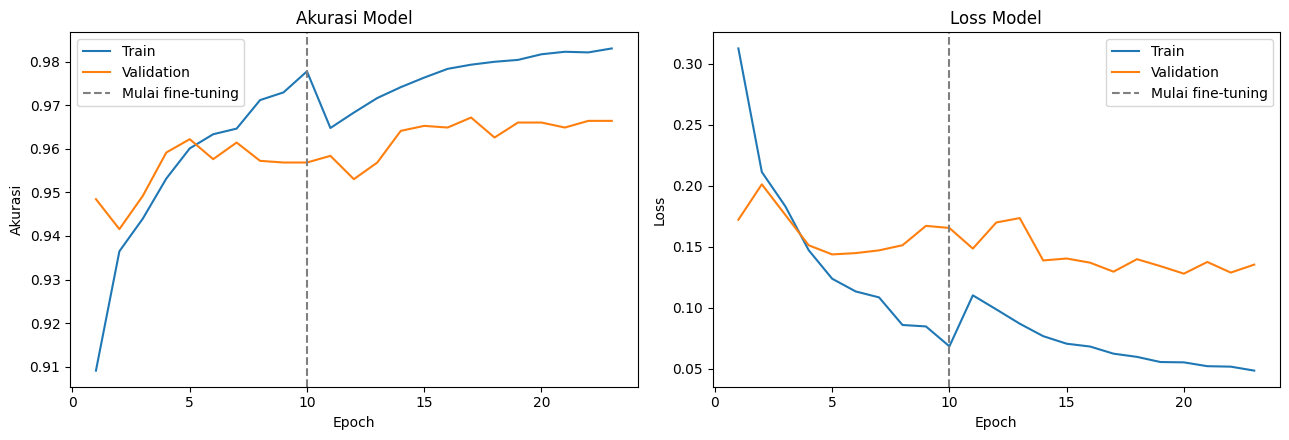

In [ ]:
hist = history_all
epochs_range = range(1, len(hist["accuracy"]) + 1)

plt.figure(figsize=(13, 4.5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, hist["accuracy"], label="Train")
plt.plot(epochs_range, hist["val_accuracy"], label="Validation")
plt.axvline(N_PHASE1, color="gray", linestyle="--", label="Mulai fine-tuning")
plt.title("Akurasi Model")
plt.xlabel("Epoch")
plt.ylabel("Akurasi")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, hist["loss"], label="Train")
plt.plot(epochs_range, hist["val_loss"], label="Validation")
plt.axvline(N_PHASE1, color="gray", linestyle="--", label="Mulai fine-tuning")
plt.title("Loss Model")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

   butterfly      0.972     0.986     0.979       212
         cat      0.946     0.952     0.949       167
     chicken      0.980     0.955     0.967       310
         cow      0.817     0.952     0.879       187
         dog      0.970     0.940     0.955       487
    elephant      0.973     0.979     0.976       145
       horse      0.945     0.913     0.928       263
       sheep      0.914     0.929     0.921       182
      spider      0.990     0.990     0.990       483
    squirrel      0.989     0.952     0.970       187

    accuracy                          0.956      2623
   macro avg      0.950     0.955     0.951      2623
weighted avg      0.958     0.956     0.956      2623



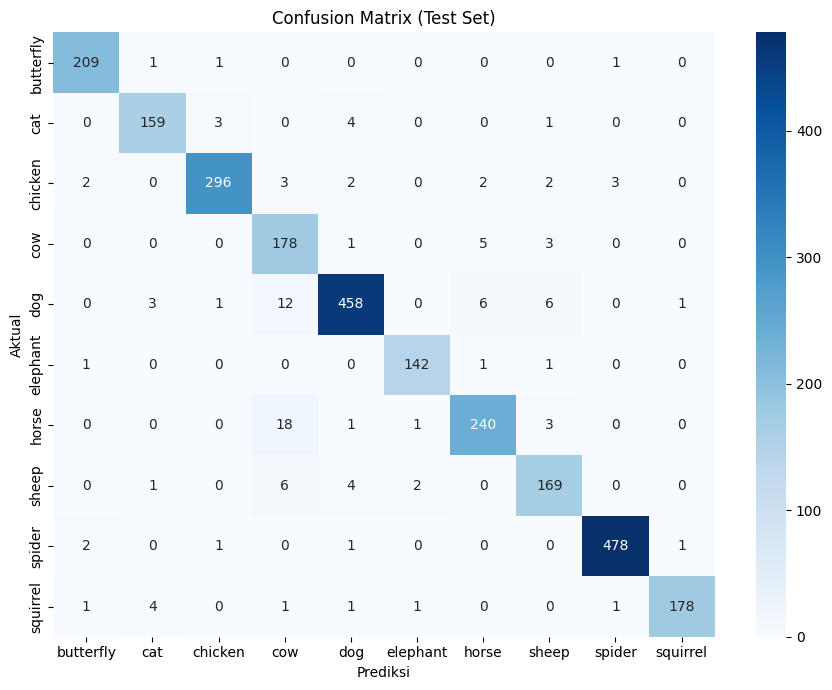

In [ ]:
test_gen.reset()
y_prob = model.predict(test_gen, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_gen.classes

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

## Konversi Model

### SavedModel

In [ ]:
os.makedirs("submission_b", exist_ok=True)
SAVED_DIR = "submission_b/saved_model"
if os.path.exists(SAVED_DIR):
    shutil.rmtree(SAVED_DIR)

try:
    model.export(SAVED_DIR)
except AttributeError:
    tf.saved_model.save(model, SAVED_DIR)

print(os.listdir(SAVED_DIR))

Saved artifact at 'submission_b/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  134687579031312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687592876176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687592878672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687592875792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687592884816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687592874448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687592875984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687593093392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687592885008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134687592884624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

### TF-Lite

In [ ]:
os.makedirs("submission_b/tflite", exist_ok=True)

converter = tf.lite.TFLiteConverter.from_saved_model(SAVED_DIR)
tflite_model = converter.convert()

with open("submission_b/tflite/model.tflite", "wb") as f:
    f.write(tflite_model)

with open("submission_b/tflite/label.txt", "w") as f:
    f.write("\n".join(class_names))

print(os.listdir("submission_b/tflite"))

['model.tflite', 'label.txt']


### TFJS

In [ ]:
!pip install -q -U packaging setuptools tensorflow_hub 2>/dev/null

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 2.0 MB/s eta 0:00:00


In [ ]:
import os
import setuptools
import numpy as np

for alias, target in {"object": object, "bool": bool, "float": float, "int": int}.items():
    if not hasattr(np, alias):
        setattr(np, alias, target)

from tensorflowjs.converters import convert

convert([
    "--input_format=tf_saved_model",
    "--output_format=tfjs_graph_model",
    "submission_b/saved_model",
    "submission_b/tfjs_model",
])
print(os.listdir("submission_b/tfjs_model"))

Writing weight file submission_b/tfjs_model/model.json...
['group1-shard4of5.bin', 'group1-shard3of5.bin', 'group1-shard1of5.bin', 'group1-shard5of5.bin', 'group1-shard2of5.bin', 'model.json']


### requirements.txt

In [ ]:
import importlib.metadata as md

pkgs = ["tensorflow", "tensorflowjs", "numpy", "pandas", "matplotlib", "seaborn",
        "Pillow", "scikit-learn", "kagglehub"]
with open("submission_b/requirements.txt", "w") as f:
    for p in pkgs:
        try:
            f.write(f"{p}=={md.version(p)}\n")
        except md.PackageNotFoundError:
            f.write(f"{p}\n")

print(open("submission_b/requirements.txt").read())

tensorflow==2.21.0
tensorflowjs==3.18.0
numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
Pillow==11.3.0
scikit-learn==1.6.1
kagglehub==1.0.2



## Inference (Optional)

Inference menggunakan model **TF-Lite** pada beberapa gambar dari test set.

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


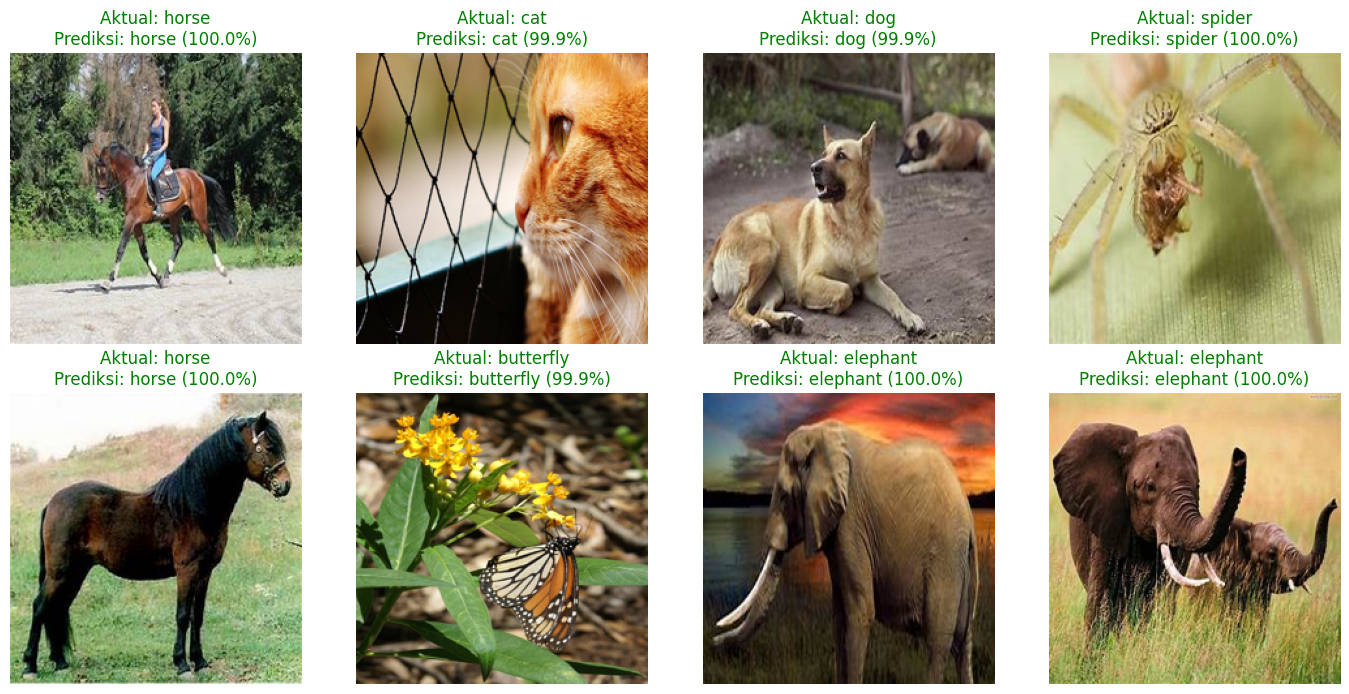

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

IMG_SIZE = (224, 224)
SPLIT_DIR = "dataset_split"

interpreter = tf.lite.Interpreter(model_path="submission_b/tflite/model.tflite")
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

with open("submission_b/tflite/label.txt") as f:
    labels = [l.strip() for l in f.readlines()]

def predict_tflite(img_path):
    img = Image.open(img_path).convert("RGB").resize(IMG_SIZE)
    x = np.expand_dims(np.array(img, dtype=np.float32) / 255.0, axis=0)
    interpreter.set_tensor(input_details[0]["index"], x)
    interpreter.invoke()
    probs = interpreter.get_tensor(output_details[0]["index"])[0]
    return img, labels[int(np.argmax(probs))], float(np.max(probs))

test_files = [(os.path.join(SPLIT_DIR, "test", c, f), c)
              for c in os.listdir(f"{SPLIT_DIR}/test")
              for f in os.listdir(os.path.join(SPLIT_DIR, "test", c))]
samples = random.sample(test_files, 8)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (path, actual) in zip(axes.ravel(), samples):
    img, pred, conf = predict_tflite(path)
    ax.imshow(img)
    ax.set_title(f"Aktual: {actual}\nPrediksi: {pred} ({conf*100:.1f}%)",
                 color="green" if pred == actual else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()